# Duy · U-Net và tích hợp đồ án

Chạy forward của U-Net A, theo dõi các tầng encoder/decoder và đối chiếu khóa thí nghiệm của A/B/C. Phần cuối xem lại minh chứng kiểm tra và chẩn đoán học thuộc hai ảnh train.

Notebook đã lưu sẵn bảng và hình. Để chạy lại, chọn kernel Python của đồ án trong VS Code hoặc Jupyter rồi bấm **Run All**. Môi trường dùng các gói trong [requirements.txt](../../../requirements.txt) và [requirements-notebook.txt](../../../requirements-notebook.txt).

In [1]:
from pathlib import Path
import json
import sys

cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "unet-vs-unetplusplus-polyp")
root = next(
    (folder for folder in candidates if (folder / "project.py").is_file()
     and (folder / "configs" / "protocol_lock.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục đồ án hoặc thư mục members/<tên>/works_done.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colors = {"A": "#345e86", "B": "#b76b21", "C": "#187c70"}

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

from PIL import Image as PILImage

def show_saved_image(path, max_width=1050, max_height=650):
    with PILImage.open(path) as image:
        image.thumbnail((max_width, max_height), PILImage.Resampling.LANCZOS)
        display(image)

## Forward U-Net A theo cấu hình của nhóm

[unet.py](unet.py) định nghĩa bốn tầng encoder, bottleneck, bốn tầng decoder với skip connection nối trực tiếp và một head 1×1. [model_factory.py](model_factory.py) khởi tạo mô hình từ cấu hình. Forward dưới đây dùng đầu vào 256×256 và trọng số khởi tạo để đo kích thước tensor.

In [2]:
import torch

from members.duy.works_done.model_factory import build_model
from members.duy.works_done.unet import count_parameters

torch.set_num_threads(2)
cfg = read_json(root / "configs" / "unet.json")
model = build_model(cfg["model"], **cfg["model_kwargs"]).eval()
height, width = cfg["image_size"]
image = torch.zeros(1, cfg["model_kwargs"]["in_channels"], height, width)
stages = ["encoder1", "encoder2", "encoder3", "encoder4", "bottleneck",
          "decoder4", "decoder3", "decoder2", "decoder1", "head"]
output_shapes = {"input": tuple(image.shape)}

def record_shape(name):
    def hook(_module, _inputs, output):
        output_shapes[name] = tuple(output.shape)
    return hook

hooks = [getattr(model, name).register_forward_hook(record_shape(name)) for name in stages]
try:
    with torch.inference_mode():
        logits = model(image)
finally:
    for handle in hooks:
        handle.remove()

shapes = pd.DataFrame.from_dict(output_shapes, orient="index", columns=["N", "C", "H", "W"])
shapes.index.name = "Tầng"
print(f"Tham số: {count_parameters(model):,} | Output logits: {tuple(logits.shape)}")
display(shapes)

Tham số: 7,760,097 | Output logits: (1, 1, 256, 256)


,N,C,H,W
Tầng,,,,
input,1,3,256,256
encoder1,1,32,256,256
encoder2,1,64,128,128
encoder3,1,128,64,64
encoder4,1,256,32,32
bottleneck,1,512,16,16
decoder4,1,256,32,32
decoder3,1,128,64,64
decoder2,1,64,128,128


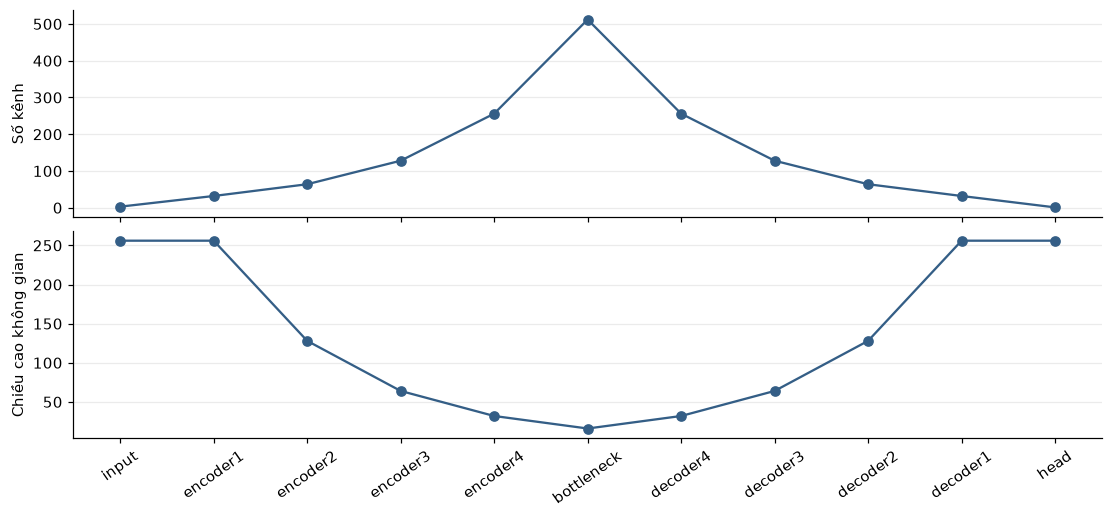

In [3]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 4.6), layout="constrained")
for ax, column, label in zip(axes, ["C", "H"], ["Số kênh", "Chiều cao không gian"]):
    ax.plot(shapes.index, shapes[column], marker="o", color=colors["A"])
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)
axes[-1].tick_params(axis="x", rotation=35)
plt.show()

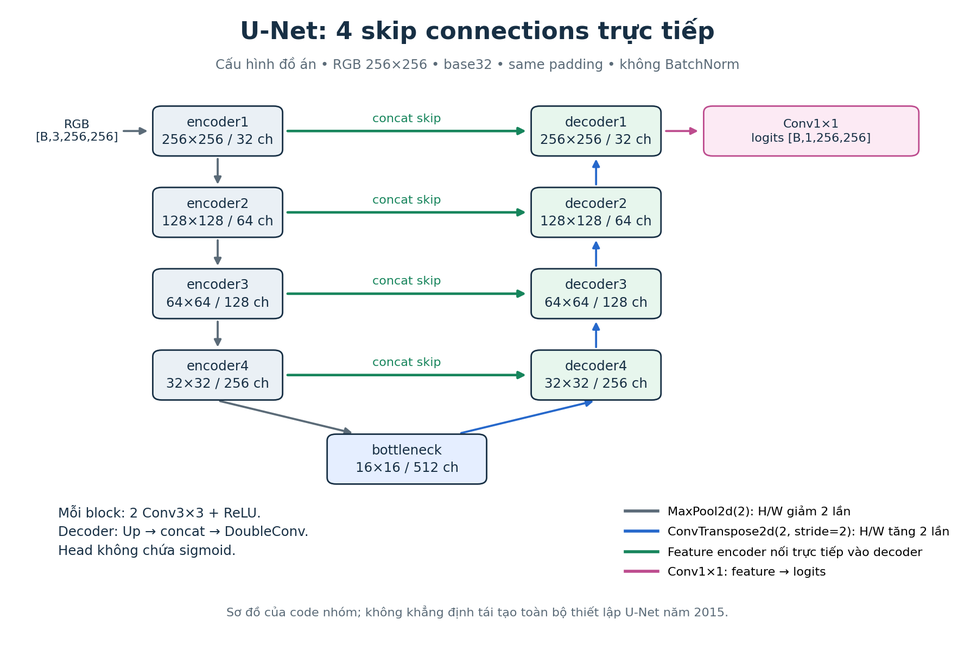

In [4]:
show_saved_image(root / "members/phuc/works_done/artifacts/architecture/unet_course_topology.png")

## Factory và khóa trước đánh giá

[lock_protocol.py](lock_protocol.py) ghi lại cấu hình, manifest và SHA-256 của checkpoint được chọn bằng validation. Bảng kiểm tra sự hiện diện của trọng số và đối chiếu SHA-256 nếu có tệp. CLI tích hợp nằm trong [project.py](../../../project.py) và [CacFileSource.py](../../../CacFileSource.py).

In [5]:
from members.tri.works_done.checkpoint_io import sha256_file

lock = read_json(root / "configs/protocol_lock.json")
manifest = root / lock["experiments"][0]["config"]["manifest"]
print(f"Trạng thái khóa: {lock['status']}")
print(f"Manifest khớp SHA-256: {sha256_file(manifest) == lock['manifest_sha256']}")
print(f"Split: {lock['split_counts']}")

rows = []
for entry in lock["experiments"]:
    path = root / entry["checkpoint_path"]
    checkpoint_status = "Thiếu tệp"
    if path.is_file():
        checkpoint_status = (
            "Khớp SHA-256" if sha256_file(path) == entry["checkpoint_sha256"] else "Sai SHA-256"
        )
    kwargs = entry["config"]["model_kwargs"]
    candidate = build_model(entry["model"], **kwargs)
    rows.append({
        "ID": entry["label"],
        "Mô hình": type(candidate).__name__,
        "Deep supervision": kwargs.get("deep_supervision", False),
        "Tham số": count_parameters(candidate),
        "Epoch đã chọn": read_json(path.parent / "summary.json")["best"]["epoch"],
        "Checkpoint": checkpoint_status,
    })
display(pd.DataFrame(rows).set_index("ID"))

Trạng thái khóa: locked_before_test
Manifest khớp SHA-256: True
Split: {'train': 700, 'test': 150, 'val': 150}


,Mô hình,Deep supervision,Tham số,Epoch đã chọn,Checkpoint
ID,,,,,
A,UNet,False,7760097,50,Thiếu tệp
B,UNetPlusPlus,False,9042177,49,Thiếu tệp
C,UNetPlusPlus,True,9042276,48,Thiếu tệp


## Minh chứng kiểm tra và báo cáo

[check_unet.py](check_unet.py) kiểm tra forward, gradient và lưu/nạp trọng số. [verify_project.py](verify_project.py) chạy các bài kiểm thử tích hợp. [overfit_train_subset.py](overfit_train_subset.py) đo khả năng học thuộc hai ảnh train. [report_figures.py](report_figures.py), [build_report.py](build_report.py) và [build_slides.py](build_slides.py) dùng kết quả đã lưu để dựng hình và tài liệu.

In [6]:
artifacts = root / "members/duy/works_done/artifacts"
check = read_json(artifacts / "model_check.json")
verification = read_json(root / "results/verification/test_summary.json")
display(pd.DataFrame([{
    "Kiểm tra U-Net": check["status"],
    "Gradient hữu hạn": check["all_gradients_finite"],
    "Sai số logits sau lưu/nạp": check["save_load_max_abs_error"],
    "Bài kiểm thử tích hợp": verification["tests_run"],
    "Lỗi": verification["failure_count"] + verification["error_count"],
}]))

,Kiểm tra U-Net,Gradient hữu hạn,Sai số logits sau lưu/nạp,Bài kiểm thử tích hợp,Lỗi
0,passed,True,0.0,48,0


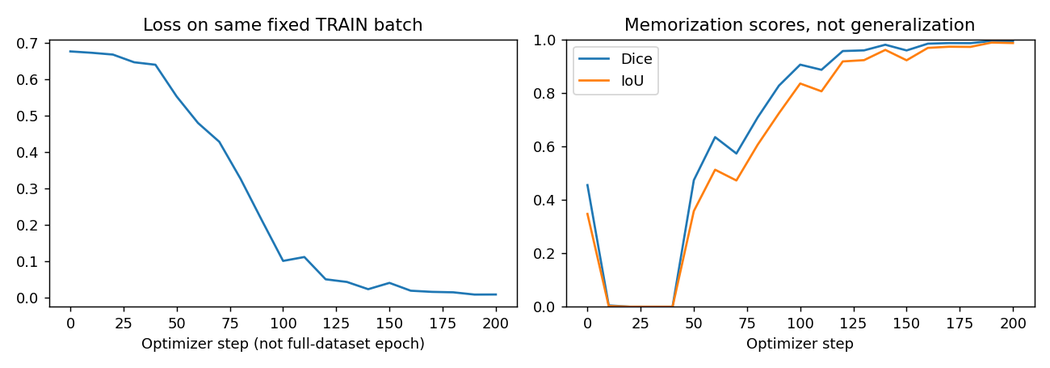

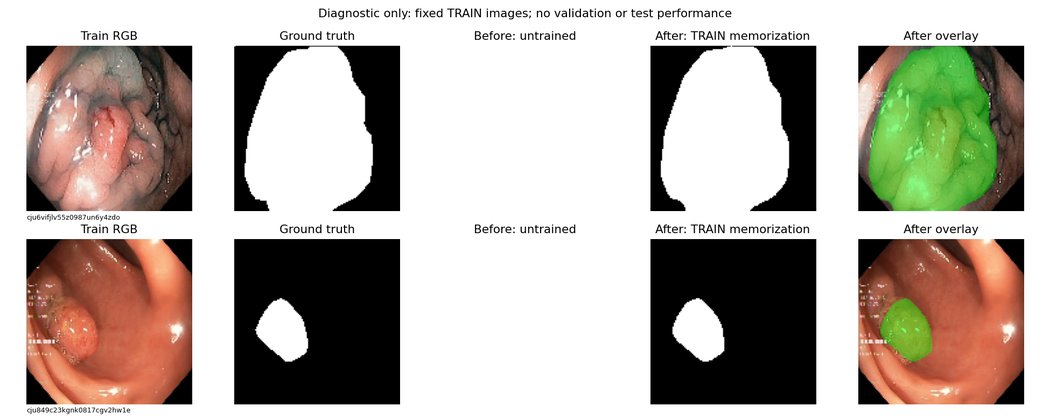

In [7]:
show_saved_image(artifacts / "overfit_diagnostic/diagnostic_curve.png")
show_saved_image(artifacts / "overfit_diagnostic/train_memorization.png")

Các đường loss và Dice ở trên đo trên hai ảnh train của bài chẩn đoán. Điểm holdout của A/B/C nằm trong [notebook của Trí](../../tri/works_done/Tri_Danh_Gia_Va_Du_Doan.ipynb).